# ArrheniusStateSurrogate — training and diagnostics

Hybrid model: keeps `ArrheniusNN`'s Arrhenius rate law + hard mass-conservation
structure for the species update, but advances the state with one Euler step
and trains the loss in normalized state-space (Z-scored log-Y, Z-scored T)
instead of raw rate-space. See `models/ArrheniusStateNN.py` for the model
itself.

Run cells in order: data loading -> training -> diagnostics.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import torch
import cantera as ct
import matplotlib.pyplot as plt

from models.ArrheniusStateSurrogate import ArrheniusStateSurrogate

## Load data and build (t, t+dt) pairs within each trajectory

In [2]:
df = pd.read_csv("../data/raw/h2o2_trajectories.csv")
species_cols = [c.replace("Y_", "") for c in df.columns if c.startswith("Y_")]


def build_pairs(d):
    """Consecutive rows within the same trajectory become one (t, t+dt) training pair."""
    rows = []
    for traj_id, g in d.groupby("traj_idx"):
        g = g.sort_values("t").reset_index(drop=True)
        for i in range(len(g) - 1):
            rows.append({
                "T": g.loc[i, "T"], "T_next": g.loc[i + 1, "T"],
                "rho": g.loc[i, "rho"],
                "dt": g.loc[i + 1, "t"] - g.loc[i, "t"],
                **{f"Y_{s}": g.loc[i, f"Y_{s}"] for s in species_cols},
                **{f"Y_{s}_next": g.loc[i + 1, f"Y_{s}"] for s in species_cols},
            })
    return pd.DataFrame(rows)

## Split by TRAJECTORY (not by row) to avoid leaking correlated rows across train/val

In [3]:
traj_ids = df["traj_idx"].unique()
rng = np.random.default_rng(0)
rng.shuffle(traj_ids)
n_val = int(0.2 * len(traj_ids))
val_ids, train_ids = set(traj_ids[:n_val]), set(traj_ids[n_val:])

train_pairs = build_pairs(df[df["traj_idx"].isin(train_ids)])
val_pairs = build_pairs(df[df["traj_idx"].isin(val_ids)])

print(f"{len(train_pairs)} train pairs, {len(val_pairs)} val pairs, "
      f"{len(train_ids)} train trajectories, {len(val_ids)} val trajectories")

15840 train pairs, 3960 val pairs, 160 train trajectories, 40 val trajectories


In [4]:
def to_tensors(d):
    T = torch.tensor(d["T"].to_numpy(), dtype=torch.float32)
    T_next = torch.tensor(d["T_next"].to_numpy(), dtype=torch.float32)
    rho = torch.tensor(d["rho"].to_numpy(), dtype=torch.float32)
    dt = torch.tensor(d["dt"].to_numpy(), dtype=torch.float32)
    Y = torch.tensor(d[[f"Y_{s}" for s in species_cols]].to_numpy(), dtype=torch.float32)
    Y_next = torch.tensor(d[[f"Y_{s}_next" for s in species_cols]].to_numpy(), dtype=torch.float32)
    return T, Y, rho, dt, T_next, Y_next


T_tr, Y_tr, rho_tr, dt_tr, T_next_tr, Y_next_tr = to_tensors(train_pairs)
T_va, Y_va, rho_va, dt_va, T_next_va, Y_next_va = to_tensors(val_pairs)

## Model + normalization stats (fit on TRAIN split only)

In [5]:
gas = ct.Solution("h2o2.yaml")
mw = np.array([gas.molecular_weights[gas.species_index(s)] for s in species_cols])

model = ArrheniusStateSurrogate(n_species=len(species_cols), molecular_weights=mw)

Y_MIN = model.Y_MIN
logY_all = torch.log(torch.clamp(torch.cat([Y_tr, Y_next_tr], dim=0), min=Y_MIN))
logdt_all = torch.log(torch.clamp(dt_tr, min=1e-12))
dT_all = T_next_tr - T_tr

model.set_norm_stats(
    logY_mean=logY_all.mean(dim=0), logY_std=logY_all.std(dim=0),
    T_mean=torch.cat([T_tr, T_next_tr]).mean(), T_std=torch.cat([T_tr, T_next_tr]).std(),
    logdt_mean=logdt_all.mean(), logdt_std=logdt_all.std(),
    dT_std=dT_all.std(),
)

opt = torch.optim.Adam(model.parameters(), lr=1e-3)

## Train\n\nLoss is computed in normalized state-space (Z-scored log-Y, Z-scored T) against the true next state, not raw log|wdot| -- this is what fixes the dynamic-range / ignition-spike imbalance problem from the earlier rate-based model. Gradient clipping smooths the occasional unstable-batch spikes seen in earlier runs.

In [6]:
n_epochs = 200
batch_size = 512
n_train = T_tr.shape[0]

train_losses, val_losses, val_epochs = [], [], []

for epoch in range(n_epochs):
    perm = torch.randperm(n_train)
    total_loss = 0.0
    for i in range(0, n_train, batch_size):
        idx = perm[i:i + batch_size]

        T_next_pred, Y_next_pred, info = model(T_tr[idx], Y_tr[idx], rho_tr[idx], dt_tr[idx])

        Tn_pred = model.normalize_T(T_next_pred)
        Tn_true = model.normalize_T(T_next_tr[idx])
        logYn_pred = model.normalize_Y(Y_next_pred)
        logYn_true = model.normalize_Y(Y_next_tr[idx])

        loss = torch.nn.functional.mse_loss(Tn_pred, Tn_true) \
             + torch.nn.functional.mse_loss(logYn_pred, logYn_true)

        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        opt.step()
        total_loss += loss.item() * len(idx)

    train_losses.append(total_loss / n_train)

    if epoch % 10 == 0:
        with torch.no_grad():
            T_next_pred_v, Y_next_pred_v, info_v = model(T_va, Y_va, rho_va, dt_va)
            Tn_pred_v = model.normalize_T(T_next_pred_v)
            Tn_true_v = model.normalize_T(T_next_va)
            logYn_pred_v = model.normalize_Y(Y_next_pred_v)
            logYn_true_v = model.normalize_Y(Y_next_va)
            val_loss = torch.nn.functional.mse_loss(Tn_pred_v, Tn_true_v) \
                     + torch.nn.functional.mse_loss(logYn_pred_v, logYn_true_v)
        val_losses.append(val_loss.item())
        val_epochs.append(epoch)
        print(f"epoch {epoch:4d}  train {total_loss/n_train:.4f}  val {val_loss.item():.4f}")

epoch    0  train 421892433603871.5625  val 0.0148
epoch   10  train 0.0147  val 0.0089
epoch   20  train 0.0098  val 0.0077
epoch   30  train 0.0096  val 0.0070
epoch   40  train 0.0091  val 0.0080
epoch   50  train 0.0086  val 0.0067
epoch   60  train 0.0082  val 0.0066
epoch   70  train 0.0077  val 0.0060
epoch   80  train 0.0094  val 0.0065
epoch   90  train 0.0076  val 0.0060
epoch  100  train 0.0078  val 0.0060
epoch  110  train 0.0071  val 0.0056
epoch  120  train 0.0071  val 0.0057
epoch  130  train 0.0094  val 0.0064
epoch  140  train 0.0086  val 0.0059
epoch  150  train 0.0081  val 0.0057
epoch  160  train 0.0074  val 0.0057
epoch  170  train 0.0075  val 0.0057
epoch  180  train 0.0070  val 0.0056
epoch  190  train 0.0070  val 0.0056


## Diagnostics: learning curve + rollout on a held-out trajectory\n\nRollout feeds the model's own predictions back in as the next input (except `rho`, which is fed from the true trajectory at each step -- this model doesn't predict density evolution, see `ArrheniusStateNN.py` docstring). This is the honest test of whether errors compound over a full trajectory, not just single-step accuracy.

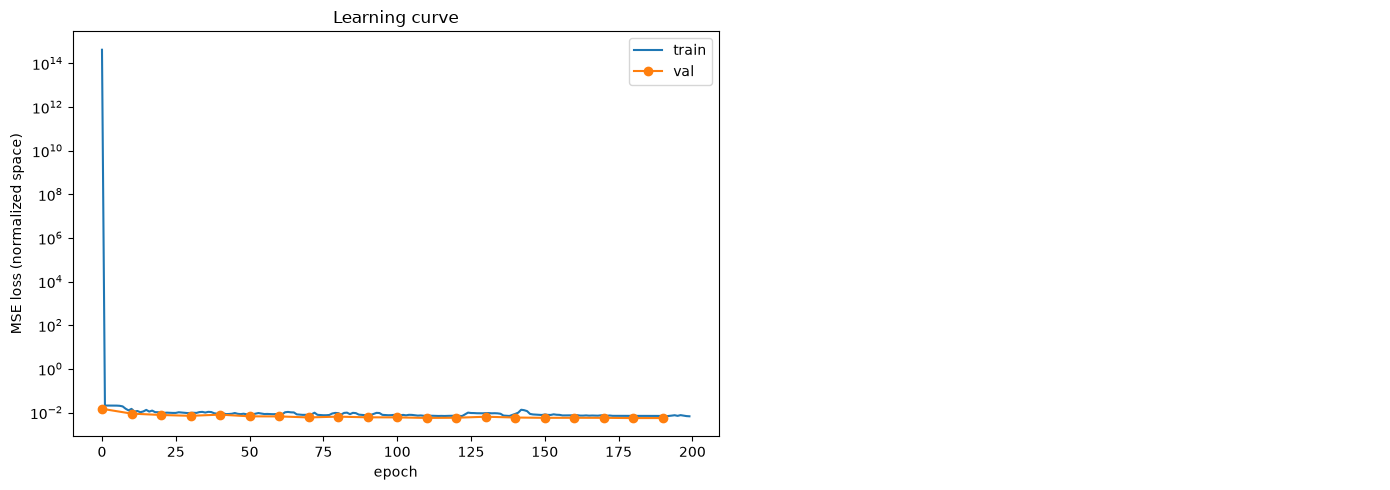

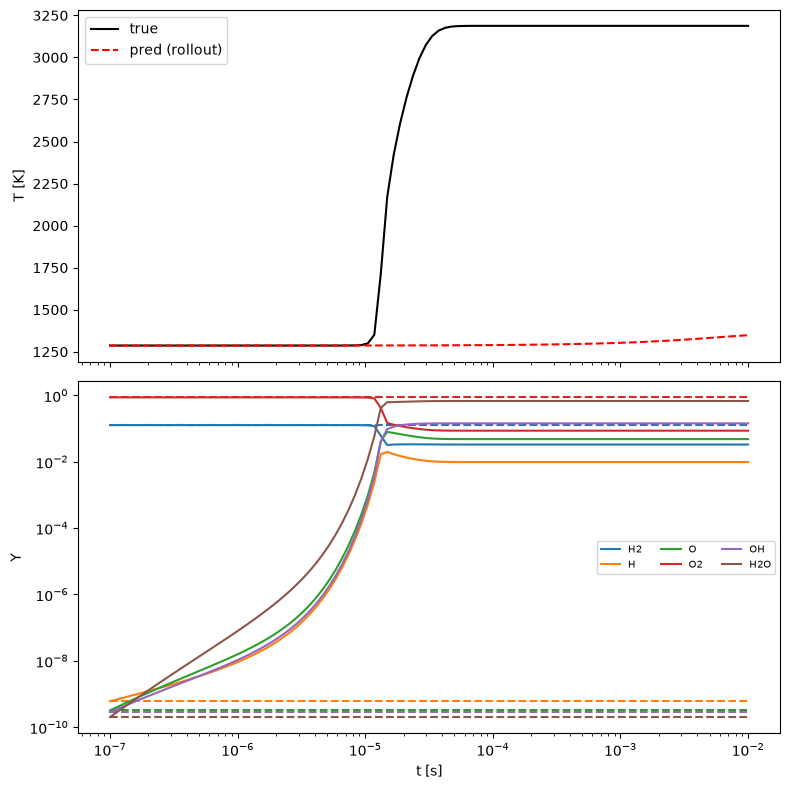

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ---- Learning curve ----
axes[0].plot(train_losses, label="train")
axes[0].plot(val_epochs, val_losses, label="val", marker="o")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("MSE loss (normalized space)")
axes[0].set_yscale("log")
axes[0].legend()
axes[0].set_title("Learning curve")
axes[1].axis("off")  # unused -- rollout renders as its own figure below
plt.tight_layout()
plt.show()

# ---- Rollout on one held-out trajectory ----
traj_id = list(val_ids)[0]
traj = df[df["traj_idx"] == traj_id].sort_values("t").reset_index(drop=True)

T0 = torch.tensor([traj.loc[0, "T"]], dtype=torch.float32)
Y0 = torch.tensor([[traj.loc[0, f"Y_{s}"] for s in species_cols]], dtype=torch.float32)
t_arr = traj["t"].to_numpy()
rho_arr = traj["rho"].to_numpy()   # true density trajectory -- fed in, not predicted

T_rollout = [T0.item()]
Y_rollout = [Y0.numpy()[0]]

T_cur, Y_cur = T0, Y0
with torch.no_grad():
    for i in range(len(t_arr) - 1):
        dt = torch.tensor([t_arr[i + 1] - t_arr[i]], dtype=torch.float32)
        rho_cur = torch.tensor([rho_arr[i]], dtype=torch.float32)
        T_cur, Y_cur, _ = model(T_cur, Y_cur, rho_cur, dt)
        T_rollout.append(T_cur.item())
        Y_rollout.append(Y_cur.numpy()[0])

T_rollout = np.array(T_rollout)
Y_rollout = np.array(Y_rollout)
Y_true = traj[[f"Y_{s}" for s in species_cols]].to_numpy()

fig2, axes2 = plt.subplots(2, 1, figsize=(8, 8), sharex=True)
axes2[0].plot(t_arr, traj["T"], label="true", color="black")
axes2[0].plot(t_arr, T_rollout, label="pred (rollout)", color="red", linestyle="--")
axes2[0].set_ylabel("T [K]")
axes2[0].set_xscale("log")
axes2[0].legend()

n_show = min(6, len(species_cols))
for i in range(n_show):
    axes2[1].plot(t_arr, Y_true[:, i], color=f"C{i}", label=species_cols[i])
    axes2[1].plot(t_arr, Y_rollout[:, i], color=f"C{i}", linestyle="--")
axes2[1].set_xlabel("t [s]")
axes2[1].set_ylabel("Y")
axes2[1].set_yscale("log")
axes2[1].set_xscale("log")
axes2[1].legend(fontsize=7, ncol=3)

plt.tight_layout()
plt.show()